# 02 — REINFORCE in JAX: CartPole-v1

**Goal.** Implement and compare four Monte Carlo policy-gradient estimators, using JAX, Flax, Optax, and Gymnax.

1. Full-trajectory REINFORCE
2. Reward-to-go REINFORCE
3. Reward-to-go with a constant baseline
4. Reward-to-go with a learned value baseline

The notebook includes environment sanity checks, training, reproducible evaluation, gradient-noise diagnostics, and plots. It is designed to run top-to-bottom on CPU or GPU.

**Methodological note:** the learned value baseline is fitted to Monte Carlo returns; this is **not** bootstrapped actor–critic. All policy updates remain on-policy.


In [1]:
# Run once in a fresh environment, then restart the kernel if necessary.
# %pip install -q "jax>=0.4.30" "flax>=0.10" "optax>=0.2.3" "gymnax>=0.0.8" matplotlib pandas


## 1. Policy-gradient derivation

For a trajectory $\tau=(s_0,a_0,\ldots,s_{T-1},a_{T-1})$ drawn from $\pi_\theta$, the score-function identity gives

$\nabla_\theta J(\theta)=\mathbb E_{\tau\sim\pi_\theta}[\sum_{t=0}^{T-1}\nabla_\theta\log\pi_\theta(a_t|s_t)R(\tau)]$.

For a discounted episodic objective, define $G_t=\sum_{k=t}^{T-1}\gamma^{k-t}r_k$. The **causal reward-to-go estimator** is

$\hat g=\sum_{t=0}^{T-1}\gamma^t\nabla_\theta\log\pi_\theta(a_t|s_t)(G_t-b(s_t))$.

The factor $\gamma^t$ is needed when estimating the gradient of the *start-state discounted return* $J=\mathbb E[\sum_t\gamma^t r_t]$. It is sometimes omitted in practical implementations; we keep it here for consistency. A baseline independent of the current action does not change the expectation of the score-function estimator. The value network is trained by regression to Monte Carlo $G_t$ with stopped-gradient targets.

**Full-trajectory estimator:** $\sum_t\nabla\log\pi(a_t|s_t)\,R_\gamma$, where $R_\gamma=\sum_k\gamma^k r_k$. This is an unbiased score-function estimator for the same discounted objective, but generally has higher variance.


In [2]:
import jax
import jax.numpy as jnp
import flax.linen as nn
import optax
import gymnax
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functools import partial

print("JAX:", jax.__version__, "| devices:", jax.devices())
env, env_params = gymnax.make("CartPole-v1")
OBS_DIM, N_ACTIONS = 4, 2


JAX: 0.11.1 | devices: [CudaDevice(id=0), CudaDevice(id=1)]


## 2. Configuration and networks

In [3]:
from dataclasses import dataclass

@dataclass(frozen=True)
class Config:
    seed: int = 0
    gamma: float = 0.99
    batch_episodes: int = 16
    updates: int = 350
    max_steps: int = 500
    policy_lr: float = 1e-3
    value_lr: float = 2e-3
    value_epochs: int = 4
    hidden: int = 64
    eval_episodes: int = 100

CFG = Config()
METHODS = ("full", "rtg", "constant", "value")

class MLP(nn.Module):
    output_dim: int
    hidden: int = 64

    @nn.compact
    def __call__(self, x):
        x = nn.tanh(nn.Dense(self.hidden)(x))
        x = nn.tanh(nn.Dense(self.hidden)(x))
        return nn.Dense(self.output_dim)(x)

policy_net = MLP(N_ACTIONS, CFG.hidden)
value_net = MLP(1, CFG.hidden)


## 3. Batched episodic rollout

All methods share the same rollout function. Gymnax is fully JAX-compatible. After an episode terminates, its remaining time slots are masked out. This avoids including rewards or gradients from post-terminal transitions.

We distinguish **training episodes** (sampled actions) from **evaluation episodes** (sampled or greedy actions). The Gymnax time-limit is also enforced by the rollout horizon.


In [4]:
def init_parameters(key):
    pkey, vkey = jax.random.split(key)
    dummy = jnp.zeros((OBS_DIM,), dtype=jnp.float32)
    return policy_net.init(pkey, dummy), value_net.init(vkey, dummy)

def rollout_one(policy_params, key, max_steps=500, greedy=False):
    reset_key, loop_key = jax.random.split(key)
    obs, env_state = env.reset(reset_key, env_params)

    def step(carry, t):
        obs, env_state, rng, alive = carry
        rng, act_key, env_key = jax.random.split(rng, 3)
        logits = policy_net.apply(policy_params, obs)
        sampled = jax.random.categorical(act_key, logits)
        action = jnp.argmax(logits) if greedy else sampled
        next_obs, next_state, reward, done, *_ = env.step(
            env_key, env_state, action, env_params
        )
        # The terminal transition is valid; only subsequent steps are padded.
        valid = alive
        reward = jnp.where(valid, reward, 0.0)
        next_obs = jnp.where(valid, next_obs, obs)
        next_state = jax.tree_util.tree_map(
            lambda old, new: jnp.where(valid, new, old), env_state, next_state
        )
        next_alive = alive & (~done)
        item = (obs, action, reward, valid)
        return (next_obs, next_state, rng, next_alive), item

    _, (obs, actions, rewards, valid) = jax.lax.scan(
        step, (obs, env_state, loop_key, jnp.bool_(True)),
        jnp.arange(max_steps)
    )
    return obs, actions, rewards, valid

@partial(jax.jit, static_argnames=("max_steps", "greedy"))
def rollout_batch(policy_params, keys, max_steps=500, greedy=False):
    return jax.vmap(
        lambda k: rollout_one(policy_params, k, max_steps, greedy)
    )(keys)

def discounted_returns(rewards, gamma):
    def step(future, r):
        total = r + gamma * future
        return total, total
    _, returns = jax.lax.scan(
        step, jnp.zeros_like(rewards[:, 0]),
        jnp.swapaxes(rewards, 0, 1)[::-1]
    )
    return jnp.swapaxes(returns[::-1], 0, 1)

p0, v0 = init_parameters(jax.random.PRNGKey(CFG.seed))
example_keys = jax.random.split(jax.random.PRNGKey(100), 3)
ex_obs, ex_actions, ex_rewards, ex_mask = rollout_batch(
    p0, example_keys, CFG.max_steps
)
assert ex_obs.shape == (3, CFG.max_steps, OBS_DIM)
assert ex_mask.shape == ex_rewards.shape
print("Initial episode lengths:", np.asarray(ex_mask.sum(axis=1)))


Initial episode lengths: [57 80 18]


## 4. Four estimators and parameter updates

For the constant baseline we use a **leave-one-trajectory-out** mean of sampled discounted returns. This prevents the baseline for an episode from depending on that episode's sampled actions, which would otherwise introduce finite-batch bias.

The value baseline is evaluated with the *pre-update* value parameters. We stop gradients through all advantage targets. We normalize the actor loss by the **number of episodes**, not the number of valid time steps, to retain the episodic policy-gradient objective's weighting.


In [5]:
def make_optimizer(lr):
    return optax.chain(optax.clip_by_global_norm(1.0), optax.adam(lr))

policy_opt = make_optimizer(CFG.policy_lr)
value_opt = make_optimizer(CFG.value_lr)

def policy_loss(params, value_params, batch, method, gamma):
    obs, actions, rewards, mask = batch
    B, T = rewards.shape
    rtg = discounted_returns(rewards, gamma)
    weights = gamma ** jnp.arange(T, dtype=rewards.dtype)
    logits = policy_net.apply(params, obs)
    log_probs = jax.nn.log_softmax(logits, axis=-1)
    selected = jnp.take_along_axis(log_probs, actions[..., None], axis=-1)[..., 0]

    if method == "full":
        # Score-function estimator of E[sum gamma^t r_t].
        full_return = (rewards * weights[None, :]).sum(axis=1)
        advantages = jnp.broadcast_to(full_return[:, None], (B, T))
        actor_weights = jnp.ones_like(weights)
    else:
        if method == "rtg":
            baseline = 0.0
        elif method == "constant":
            # Leave-one-episode-out scalar baseline for each episode.
            discounted_total = (rewards * weights[None, :]).sum(axis=1)
            baseline = ((discounted_total.sum() - discounted_total)
                        / jnp.maximum(B - 1, 1))[:, None]
            # A scalar baseline on reward-to-go is still action-independent.
        elif method == "value":
            baseline = value_net.apply(value_params, obs)[..., 0]
        else:
            raise ValueError(method)
        advantages = rtg - baseline
        actor_weights = weights
    advantages = jax.lax.stop_gradient(advantages)
    return -(selected * advantages * mask * actor_weights[None, :]).sum() / B

def critic_loss(params, batch, gamma):
    obs, _, rewards, mask = batch
    target = jax.lax.stop_gradient(discounted_returns(rewards, gamma))
    prediction = value_net.apply(params, obs)[..., 0]
    return (((prediction - target) ** 2) * mask).sum() / jnp.maximum(mask.sum(), 1)

def make_train_step(method, gamma, value_epochs):
    @jax.jit
    def step(p, v, po, vo, batch):
        loss, grads = jax.value_and_grad(policy_loss)(
            p, v, batch, method, gamma
        )
        updates, po = policy_opt.update(grads, po, p)
        p = optax.apply_updates(p, updates)
        vloss = jnp.array(0.0)
        if method == "value":
            def update_value(carry, _):
                v, vo = carry
                vloss, vg = jax.value_and_grad(critic_loss)(v, batch, gamma)
                vu, vo = value_opt.update(vg, vo, v)
                return (optax.apply_updates(v, vu), vo), vloss
            (v, vo), losses = jax.lax.scan(
                update_value, (v, vo), None, length=value_epochs
            )
            vloss = losses[-1]
        return p, v, po, vo, loss, vloss
    return step

train_steps = {
    method: make_train_step(method, CFG.gamma, CFG.value_epochs)
    for method in METHODS
}


## 5. Train all four methods

In [6]:
def train_method(method, config=CFG, seed=0):
    key = jax.random.PRNGKey(seed)
    key, init_key = jax.random.split(key)
    p, v = init_parameters(init_key)
    po, vo = policy_opt.init(p), value_opt.init(v)
    history = {"update": [], "return": [], "actor_loss": [], "critic_loss": []}
    step_fn = train_steps[method]
    for update in range(config.updates):
        key, batch_key = jax.random.split(key)
        keys = jax.random.split(batch_key, config.batch_episodes)
        batch = rollout_batch(p, keys, config.max_steps)
        episode_returns = batch[2].sum(axis=1)
        p, v, po, vo, ploss, vloss = step_fn(p, v, po, vo, batch)
        history["update"].append(update + 1)
        history["return"].append(float(episode_returns.mean()))
        history["actor_loss"].append(float(ploss))
        history["critic_loss"].append(float(vloss))
        if (update + 1) % 50 == 0:
            print(f"{method:>8} | {update+1:>4}/{config.updates} "
                  f"| train return {history['return'][-1]:6.1f}")
    return p, v, pd.DataFrame(history)

# A single training seed is a demonstration, not a robust method ranking.
trained = {}
for method in METHODS:
    print("\nTraining", method)
    trained[method] = train_method(method, seed=CFG.seed)



Training full
    full |   50/350 | train return   73.6
    full |  100/350 | train return  123.0
    full |  150/350 | train return  186.7
    full |  200/350 | train return  309.5
    full |  250/350 | train return  364.2
    full |  300/350 | train return  143.4
    full |  350/350 | train return  266.8

Training rtg
     rtg |   50/350 | train return  270.3
     rtg |  100/350 | train return  264.3
     rtg |  150/350 | train return  435.2
     rtg |  200/350 | train return  450.7
     rtg |  250/350 | train return  483.6
     rtg |  300/350 | train return  499.4
     rtg |  350/350 | train return  425.3

Training constant
constant |   50/350 | train return  307.2
constant |  100/350 | train return  497.9
constant |  150/350 | train return  497.2
constant |  200/350 | train return  487.4
constant |  250/350 | train return  500.0
constant |  300/350 | train return  500.0
constant |  350/350 | train return  500.0

Training value
   value |   50/350 | train return  269.0
   value |  

## 6. Learning curves and losses

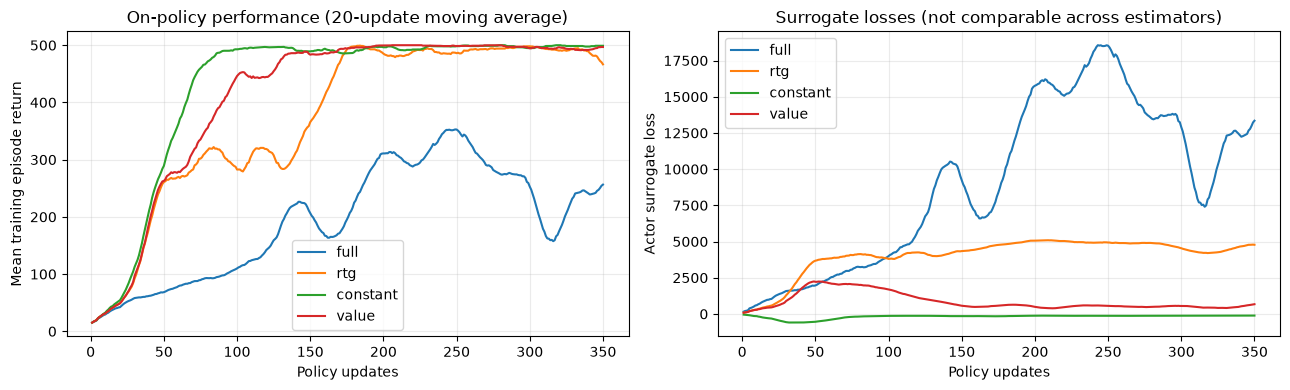

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for method, (_, _, df) in trained.items():
    smoothed = df["return"].rolling(20, min_periods=1).mean()
    axes[0].plot(df["update"], smoothed, label=method)
    axes[1].plot(df["update"], df["actor_loss"].rolling(20, min_periods=1).mean(), label=method)
axes[0].set(xlabel="Policy updates", ylabel="Mean training episode return",
            title="On-policy performance (20-update moving average)")
axes[1].set(xlabel="Policy updates", ylabel="Actor surrogate loss",
            title="Surrogate losses (not comparable across estimators)")
for ax in axes: ax.grid(alpha=.25); ax.legend()
plt.tight_layout()
plt.show()


## 7. Paired evaluation

All policies use the **same reset/environment keys**, reducing variance from initial conditions. For CartPole the maximum episode return is 500. We report mean, median, standard deviation, and a percentile bootstrap confidence interval for the mean. A greedy policy is a distinct evaluation mode, not the distribution trained by REINFORCE.


,method,mode,mean,median,std,ci_low,ci_high
0,full,sampled,282.630005,286.5,74.160004,268.13,296.45
1,full,greedy,362.350006,356.0,48.080002,353.08,371.91
2,rtg,sampled,429.179993,500.0,116.669998,406.34,451.71
3,rtg,greedy,500.000000,500.0,0.000000,500.00,500.00
4,constant,sampled,500.000000,500.0,0.000000,500.00,500.00
5,constant,greedy,500.000000,500.0,0.000000,500.00,500.00
6,value,sampled,500.000000,500.0,0.000000,500.00,500.00
7,value,greedy,500.000000,500.0,0.000000,500.00,500.00


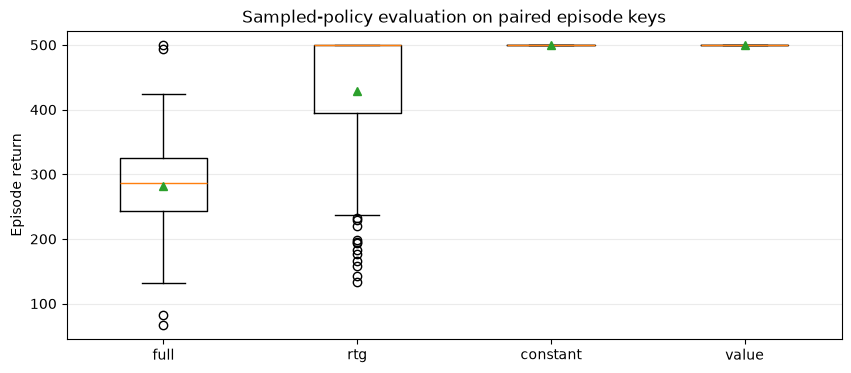

In [8]:
def evaluate(params, keys, greedy=False):
    _, _, rewards, _ = rollout_batch(params, keys, CFG.max_steps, greedy=greedy)
    return np.asarray(rewards.sum(axis=1))

def bootstrap_mean_ci(x, seed=123, repeats=2000):
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    samples = rng.choice(x, (repeats, len(x)), replace=True).mean(axis=1)
    return np.percentile(samples, [2.5, 97.5])

eval_keys = jax.random.split(jax.random.PRNGKey(2026), CFG.eval_episodes)
evaluation = {}
rows = []
for method, (p, _, _) in trained.items():
    for mode in ("sampled", "greedy"):
        scores = evaluate(p, eval_keys, greedy=(mode == "greedy"))
        evaluation[(method, mode)] = scores
        low, high = bootstrap_mean_ci(scores)
        rows.append(dict(method=method, mode=mode, mean=scores.mean(),
                         median=np.median(scores), std=scores.std(ddof=1),
                         ci_low=low, ci_high=high))
summary = pd.DataFrame(rows)
display(summary.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
data = [evaluation[(m, "sampled")] for m in METHODS]
ax.boxplot(data, tick_labels=METHODS, showmeans=True)
ax.set(title="Sampled-policy evaluation on paired episode keys",
       ylabel="Episode return")
ax.grid(axis="y", alpha=.25)
plt.show()


## 8. Gradient-noise diagnostic

We estimate variability across independent **on-policy minibatches at a fixed policy**. Each gradient is flattened, and we compute its squared distance from the average gradient. The diagnostic reports a *trace-variance estimate* of the batch gradient, not a per-parameter variance or an exact analytical variance. We compare the estimators at the same policy/value parameters to avoid confounding estimator choice with different trained policies.

**Important:** a constant baseline based on the batch's other episodes remains independent of the current episode's action, but the value baseline may be inaccurate. Therefore the learned value baseline is not guaranteed to have the lowest variance.


,method,gradient_trace_variance,mean_gradient_norm
0,full,2.703458e+06,258.130005
1,rtg,3.791254e+05,114.890999
2,constant,6.310600e+01,0.950000
3,value,1.187934e+04,20.926001


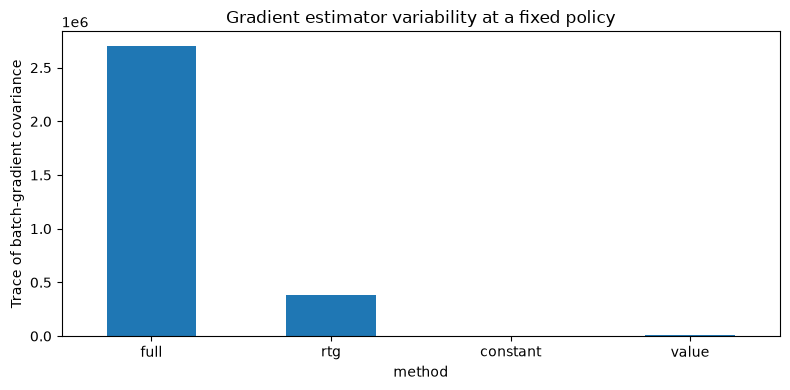

In [9]:
from jax.flatten_util import ravel_pytree

def gradient_diagnostic(reference_policy, reference_value, batches=24, seed=55):
    rng = jax.random.PRNGKey(seed)
    flat_gradients = {m: [] for m in METHODS}
    for _ in range(batches):
        rng, sub = jax.random.split(rng)
        keys = jax.random.split(sub, CFG.batch_episodes)
        batch = rollout_batch(reference_policy, keys, CFG.max_steps)
        for method in METHODS:
            grad = jax.grad(policy_loss)(
                reference_policy, reference_value, batch, method, CFG.gamma
            )
            flat_gradients[method].append(np.asarray(ravel_pytree(grad)[0]))
    results = []
    for method, gs in flat_gradients.items():
        gs = np.stack(gs)
        variance_trace = ((gs - gs.mean(0)) ** 2).sum(1).sum() / (len(gs) - 1)
        results.append({"method": method,
                        "gradient_trace_variance": variance_trace,
                        "mean_gradient_norm": np.linalg.norm(gs.mean(0))})
    return pd.DataFrame(results)

# Use a trained policy, with the trained value baseline for that same policy.
reference_p, reference_v, _ = trained["value"]
gradient_stats = gradient_diagnostic(reference_p, reference_v)
display(gradient_stats.round(3))
ax = gradient_stats.plot.bar(x="method", y="gradient_trace_variance",
                             legend=False, figsize=(8, 4))
ax.set(ylabel="Trace of batch-gradient covariance",
       title="Gradient estimator variability at a fixed policy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 9. Multiple seeds (optional but recommended)

Single-seed learning curves are insufficient for robust conclusions. The following cell retrains all four methods on independent seeds and reports final sampled-policy returns. It is computationally more expensive, so it is disabled by default.


In [10]:
RUN_MULTISEED = False
SEEDS = (0, 1, 2, 3, 4)

if RUN_MULTISEED:
    seed_results = []
    for seed in SEEDS:
        fixed_eval_keys = jax.random.split(jax.random.PRNGKey(10000 + seed), 100)
        for method in METHODS:
            p, _, _ = train_method(method, seed=seed)
            scores = evaluate(p, fixed_eval_keys)
            seed_results.append(dict(seed=seed, method=method,
                                     mean_return=scores.mean(),
                                     median_return=np.median(scores)))
    seed_df = pd.DataFrame(seed_results)
    display(seed_df.pivot(index="seed", columns="method", values="mean_return"))
    display(seed_df.groupby("method")["mean_return"].agg(["mean", "std"]))


## 10. Conclusions and next steps

**What to inspect after running:**

- Does reward-to-go reduce gradient variance relative to the full-return estimator?
- Does the constant baseline help, and is a learned state-dependent baseline better?
- Do gradient-noise differences translate to faster learning across multiple seeds?
- How different are sampled and greedy policy evaluations?

**Caveats:** CartPole is easy, policy-gradient estimates can be noisy, and a single run does not establish a general ranking. The actor surrogate loss is not directly comparable between methods. The value baseline is learned from Monte Carlo targets, not TD targets.

**Next notebook:** Actor–Critic and Generalized Advantage Estimation (GAE), where we introduce bootstrapped targets and examine bias–variance trade-offs.
